In [71]:
import time
import requests
import pandas as pd
from collections import defaultdict

# MusicBrainz requires a descriptive User-Agent
HEADERS = {
    "User-Agent": "BreakoutArtistCapstone/1.0 (gabrielle.nelson16@gmail.com)"
}
BASE_URL = "https://musicbrainz.org/ws/2"
RATE_LIMIT_SECONDS = 1.05  # be polite; MB recommends ~1 req/sec



In [72]:
def mb_get(endpoint, params):
    """
    Generic MusicBrainz GET with light rate-limit handling.
    """
    params = {**params, "fmt": "json"}
    url = f"{BASE_URL}{endpoint}"
    r = requests.get(url, headers=HEADERS, params=params, timeout=30)
    if r.status_code == 503:
        time.sleep(2)
        r = requests.get(url, headers=HEADERS, params=params, timeout=30)
    r.raise_for_status()
    time.sleep(RATE_LIMIT_SECONDS)
    return r.json()

In [73]:
def search_artist_mbid(artist_name):
    """
    Resolve an artist name to a MusicBrainz Artist MBID.
    """
    data = mb_get("/artist", {"query": f'artist:"{artist_name}"', "limit": 1})
    artists = data.get("artists", [])
    if not artists:
        return None
    return artists[0]["id"]

def get_artist_releases(artist_mbid, limit=100):
    """
    Pull releases for an artist (release activity signal).
    """
    offset = 0
    rows = []

    while True:
        data = mb_get(
            "/release",
            {
                "artist": artist_mbid,
                "limit": min(limit, 100),
                "offset": offset
            }
        )
        releases = data.get("releases", [])
        if not releases:
            break

        for rel in releases:
            rows.append({
                "artist_mbid": artist_mbid,
                "release_mbid": rel.get("id"),
                "title": rel.get("title"),
                "date": rel.get("date"),  # may be YYYY or YYYY-MM or YYYY-MM-DD
                "country": rel.get("country"),
                "status": rel.get("status"),
                "release_group_mbid": rel.get("release-group", {}).get("id"),
                "primary_type": rel.get("release-group", {}).get("primary-type"),
                "secondary_types": ",".join(rel.get("release-group", {}).get("secondary-types", []))
            })

        offset += len(releases)
        if offset >= data.get("release-count", 0):
            break

    return pd.DataFrame(rows).drop_duplicates()

In [74]:
def get_artist_recordings_with_collabs(artist_mbid, limit=100):
    """
    Pull recordings and detect collaboration/co-credit patterns.
    """
    offset = 0
    rows = []

    while True:
        data = mb_get(
            "/recording",
            {
                "artist": artist_mbid,
                "inc": "artist-credits",
                "limit": min(limit, 100),
                "offset": offset
            }
        )
        recs = data.get("recordings", [])
        if not recs:
            break

        for rec in recs:
            credits = rec.get("artist-credit", [])
            credited_artists = [
                c.get("artist", {}).get("name")
                for c in credits
                if isinstance(c, dict) and c.get("artist")
            ]
            credited_mbids = [
                c.get("artist", {}).get("id")
                for c in credits
                if isinstance(c, dict) and c.get("artist")
            ]

            rows.append({
                "artist_mbid": artist_mbid,
                "recording_mbid": rec.get("id"),
                "recording_title": rec.get("title"),
                "artist_credit_count": len(credited_artists),
                "credited_artist_names": "|".join([a for a in credited_artists if a]),
                "credited_artist_mbids": "|".join([a for a in credited_mbids if a]),
                "is_collab": 1 if len(set([a for a in credited_mbids if a])) > 1 else 0
            })

        offset += len(recs)
        if offset >= data.get("recording-count", 0):
            break

    return pd.DataFrame(rows).drop_duplicates()

In [75]:
def get_artist_tags_and_genres(artist_mbid):
    """
    Pull tag/genre-like metadata for genre pattern features.
    """
    # Some artist payloads include tags and genres when requested with inc
    data = mb_get(f"/artist/{artist_mbid}", {"inc": "tags+genres"})
    tags = data.get("tags", [])
    genres = data.get("genres", [])

    tag_rows = [{
        "artist_mbid": artist_mbid,
        "name": t.get("name"),
        "count": t.get("count", 0),
        "type": "tag"
    } for t in tags]

    genre_rows = [{
        "artist_mbid": artist_mbid,
        "name": g.get("name"),
        "count": g.get("count", 0),
        "type": "genre"
    } for g in genres]

    return pd.DataFrame(tag_rows + genre_rows)

In [76]:
def build_artist_early_signals(artist_name):
    """
    Build capstone feature set for one artist using MusicBrainz data only.
    """
    artist_mbid = search_artist_mbid(artist_name)
    if not artist_mbid:
        raise ValueError(f"Could not resolve artist MBID for: {artist_name}")

    releases = get_artist_releases(artist_mbid)
    recs = get_artist_recordings_with_collabs(artist_mbid)
    tags = get_artist_tags_and_genres(artist_mbid)

    # ---------- Release activity features ----------
    if not releases.empty:
        # Parse year from partial date strings safely
        releases["release_year"] = pd.to_numeric(
            releases["date"].astype(str).str.slice(0, 4),
            errors="coerce"
        )

        release_features = {
            "artist_mbid": artist_mbid,
            "artist_name": artist_name,
            "release_count_total": int(releases["release_mbid"].nunique()),
            "release_group_count_total": int(releases["release_group_mbid"].nunique()),
            "first_release_year": int(releases["release_year"].min()) if releases["release_year"].notna().any() else None,
            "last_release_year": int(releases["release_year"].max()) if releases["release_year"].notna().any() else None,
            "album_count": int((releases["primary_type"] == "Album").sum()),
            "single_count": int((releases["primary_type"] == "Single").sum()),
            "ep_count": int((releases["primary_type"] == "EP").sum())
        }
    else:
        release_features = {
            "artist_mbid": artist_mbid,
            "artist_name": artist_name,
            "release_count_total": 0,
            "release_group_count_total": 0,
            "first_release_year": None,
            "last_release_year": None,
            "album_count": 0,
            "single_count": 0,
            "ep_count": 0
        }

    # ---------- Collaboration network features ----------
    if not recs.empty:
        collab_features = {
            "recording_count_total": int(recs["recording_mbid"].nunique()),
            "collab_recording_count": int(recs["is_collab"].sum()),
            "collab_ratio": float(recs["is_collab"].mean()),
            "avg_artist_credit_count": float(recs["artist_credit_count"].mean())
        }

        # unique collaborator count (excluding focal artist)
        collaborators = set()
        for mbid_str in recs["credited_artist_mbids"].dropna():
            for m in mbid_str.split("|"):
                if m and m != artist_mbid:
                    collaborators.add(m)
        collab_features["unique_collaborator_count"] = int(len(collaborators))
    else:
        collab_features = {
            "recording_count_total": 0,
            "collab_recording_count": 0,
            "collab_ratio": 0.0,
            "avg_artist_credit_count": 0.0,
            "unique_collaborator_count": 0
        }

    # ---------- Genre pattern features ----------
    if not tags.empty:
        top_tags = (
            tags.sort_values("count", ascending=False)
                .head(5)["name"]
                .fillna("")
                .tolist()
        )
        genre_features = {
            "tag_genre_item_count": int(tags.shape[0]),
            "top_5_tags_genres": "|".join(top_tags),
            "total_tag_genre_votes": int(tags["count"].fillna(0).sum())
        }
    else:
        genre_features = {
            "tag_genre_item_count": 0,
            "top_5_tags_genres": "",
            "total_tag_genre_votes": 0
        }

    return pd.DataFrame([{**release_features, **collab_features, **genre_features}]), releases, recs, tags


if __name__ == "__main__":
    artists = [
        "David McComb"
    ]

    feature_rows = []
    all_releases = []
    all_recs = []
    all_tags = []

    for artist in artists:
        try:
            f, rel, rec, tag = build_artist_early_signals(artist)
            feature_rows.append(f)
            all_releases.append(rel.assign(artist_name=artist))
            all_recs.append(rec.assign(artist_name=artist))
            all_tags.append(tag.assign(artist_name=artist))
            print(f"Processed: {artist}")
        except Exception as e:
            print(f"Skipped {artist}: {e}")


Processed: David McComb


In [77]:
from IPython.display import display

features_df = pd.concat(feature_rows, ignore_index=True) if feature_rows else pd.DataFrame()
releases_df = pd.concat(all_releases, ignore_index=True) if all_releases else pd.DataFrame()
recs_df = pd.concat(all_recs, ignore_index=True) if all_recs else pd.DataFrame()
tags_df = pd.concat(all_tags, ignore_index=True) if all_tags else pd.DataFrame()

# --- US-only filter ---
# 1) Releases: keep only releases explicitly marked US
if not releases_df.empty and "country" in releases_df.columns:
    releases_df = releases_df[releases_df["country"] == "US"].copy()

# 2) Recompute features_df from US-filtered releases only
#    (for release_count, album/single/EP counts, etc.)
if not features_df.empty and not releases_df.empty:
    us_release_feats = (
        releases_df.groupby(["artist_mbid", "artist_name"], as_index=False)
        .agg(
            release_count_total=("release_mbid", "nunique"),
            release_group_count_total=("release_group_mbid", "nunique"),
            album_count=("primary_type", lambda s: (s == "Album").sum()),
            single_count=("primary_type", lambda s: (s == "Single").sum()),
            ep_count=("primary_type", lambda s: (s == "EP").sum()),
        )
    )

    # Optional: recompute first/last release year from US-only dates
    tmp = releases_df.copy()
    tmp["release_year"] = pd.to_numeric(tmp["date"].astype(str).str[:4], errors="coerce")
    years = (
        tmp.groupby(["artist_mbid", "artist_name"], as_index=False)
        .agg(
            first_release_year=("release_year", "min"),
            last_release_year=("release_year", "max"),
        )
    )

    us_release_feats = us_release_feats.merge(years, on=["artist_mbid", "artist_name"], how="left")

    # Keep non-release features from old features_df, replace release features with US-only versions
    non_release_cols = [
        c for c in features_df.columns
        if c not in {
            "release_count_total", "release_group_count_total",
            "first_release_year", "last_release_year",
            "album_count", "single_count", "ep_count"
        }
    ]

    features_df = (
        features_df[non_release_cols]
        .merge(us_release_feats, on=["artist_mbid", "artist_name"], how="left")
        .fillna({
            "release_count_total": 0,
            "release_group_count_total": 0,
            "album_count": 0,
            "single_count": 0,
            "ep_count": 0
        })
    )

# for name, df in [
#     ("features_df", features_df),
#     ("releases_df", releases_df),
#     ("recs_df", recs_df),
#     ("tags_df", tags_df),
# ]:
#     print(f"\n===== {name} (shape: {df.shape}) =====")
#     display(df.head())

# print("features_df")
# display(features_df.head())
#
# print("releases_df")
# display(releases_df.head())
#
# print("recs_df")
# display(recs_df.head())
#
# print("tags_df")
# display(tags_df.head())

releases_df is empty


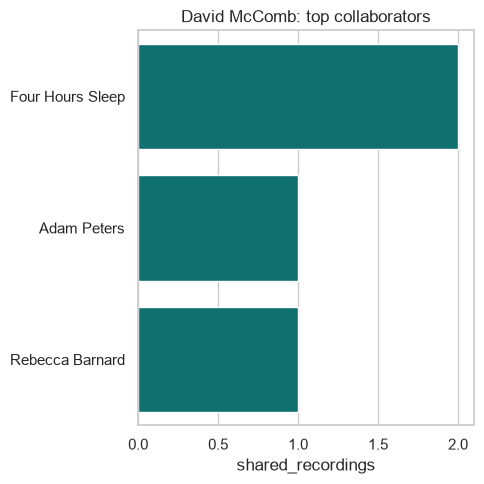

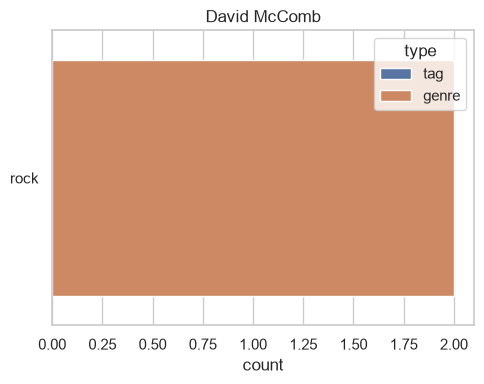

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")


def plot_release_timeline(releases_df):
    """Releases per year, split by artist."""
    if releases_df.empty:
        print("releases_df is empty")
        return
    df = releases_df.copy()
    df["release_year"] = pd.to_numeric(df["date"].astype(str).str[:4], errors="coerce")
    df = df.dropna(subset=["release_year"])
    counts = df.groupby(["release_year", "artist_name"]).size().reset_index(name="releases")

    plt.figure(figsize=(6, 3))
    sns.lineplot(data=counts, x="release_year", y="releases", hue="artist_name", marker="o")
    plt.title("Release Activity by Year (US)")
    plt.xlabel("Year")
    plt.ylabel("Number of releases")
    plt.tight_layout()
    plt.show()


sns.set_theme(style="whitegrid")


def plot_collab_strategy(features_df):
    """
    Bubble chart: x = recordings, y = collab ratio,
    bubble size = unique collaborators.
    Shows catalog size, collab reliance, and network breadth together.
    """
    if features_df.empty:
        return

    df = features_df.copy()
    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        data=df,
        x="recording_count_total",
        y="collab_ratio",
        size="unique_collaborator_count",
        hue="artist_name",
        sizes=(200, 1500),
        alpha=0.7,
        legend="brief",
    )
    for _, r in df.iterrows():
        plt.annotate(
            r["artist_name"],
            (r["recording_count_total"], r["collab_ratio"]),
            ha="center", va="center", fontsize=9,
        )

    plt.axhline(df["collab_ratio"].median(), color="gray", linestyle="--", alpha=0.5)
    plt.ylim(-0.05, 1.05)
    plt.title("Collaboration Strategy\n(bubble size = unique collaborators)")
    plt.xlabel("Total recordings")
    plt.ylabel("Collaboration ratio")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


def plot_top_collaborators(recs_df, artist_mbid_col="artist_mbid", top_n=8):
    """
    For each artist, show their most frequent collaborators
    (excluding themselves) as horizontal bars.
    """
    if recs_df.empty:
        return

    rows = []
    for _, r in recs_df.iterrows():
        names = str(r["credited_artist_names"]).split("|")
        mbids = str(r["credited_artist_mbids"]).split("|")
        for n, m in zip(names, mbids):
            if m and m != r[artist_mbid_col]:
                rows.append({"artist_name": r["artist_name"], "collaborator": n})

    collab = pd.DataFrame(rows)
    if collab.empty:
        print("No collaborators found")
        return

    counts = (
        collab.groupby(["artist_name", "collaborator"]).size()
        .reset_index(name="shared_recordings")
    )

    artists = counts["artist_name"].unique()
    fig, axes = plt.subplots(1, len(artists), figsize=(5 * len(artists), 5), squeeze=False)
    for ax, artist in zip(axes[0], artists):
        sub = counts[counts["artist_name"] == artist].nlargest(top_n, "shared_recordings")
        sns.barplot(data=sub, y="collaborator", x="shared_recordings", ax=ax, color="teal")
        ax.set_title(f"{artist}: top collaborators")
        ax.set_ylabel("")
    plt.tight_layout()
    plt.show()


def plot_collab_over_time(recs_df, releases_df):
    """
    Optional: collaboration share by release year.
    Approximates timing by matching recording titles to release titles.
    """
    merged = recs_df.merge(
        releases_df[["artist_mbid", "title", "date"]].drop_duplicates(),
        left_on=["artist_mbid", "recording_title"],
        right_on=["artist_mbid", "title"],
        how="inner",
    )
    merged["year"] = pd.to_numeric(merged["date"].astype(str).str[:4], errors="coerce")
    merged = merged.dropna(subset=["year"])
    if merged.empty:
        print("No title matches between recordings and releases")
        return

    yearly = merged.groupby(["artist_name", "year"])["is_collab"].mean().reset_index()
    plt.figure(figsize=(10, 5))
    sns.lineplot(data=yearly, x="year", y="is_collab", hue="artist_name", marker="o")
    plt.ylim(0, 1)
    plt.title("Collaboration Share Over Time")
    plt.ylabel("Share of recordings that are collabs")
    plt.tight_layout()
    plt.show()


def plot_collab_pair_heatmap(recs_df, top_n=15):
    """
    Collaboration alternative:
    Heatmap of artist-artist collaboration frequency (pair counts).
    """
    if recs_df.empty or "credited_artist_names" not in recs_df.columns:
        print("recs_df is empty or missing credited_artist_names.")
        return

    # Build pair counts from credited_artist_names
    pair_counts = {}
    for names_str in recs_df["credited_artist_names"].dropna():
        names = sorted(list(set([n.strip() for n in str(names_str).split("|") if n.strip()])))
        if len(names) < 2:
            continue
        for i in range(len(names)):
            for j in range(i + 1, len(names)):
                pair = (names[i], names[j])
                pair_counts[pair] = pair_counts.get(pair, 0) + 1

    if not pair_counts:
        print("No collaboration pairs found.")
        return

    pair_df = pd.DataFrame(
        [{"artist_a": a, "artist_b": b, "count": c} for (a, b), c in pair_counts.items()]
    )

    # Keep top artists by total pair counts for readability
    totals = (
        pd.concat([
            pair_df[["artist_a", "count"]].rename(columns={"artist_a": "artist"}),
            pair_df[["artist_b", "count"]].rename(columns={"artist_b": "artist"})
        ])
        .groupby("artist", as_index=False)["count"].sum()
        .sort_values("count", ascending=False)
        .head(top_n)
    )
    keep = set(totals["artist"])

    pair_df = pair_df[
        pair_df["artist_a"].isin(keep) & pair_df["artist_b"].isin(keep)
    ].copy()

    if pair_df.empty:
        print("Not enough pair data after top_n filtering.")
        return

    # Symmetric matrix
    artists = sorted(list(keep))
    mat = pd.DataFrame(0, index=artists, columns=artists, dtype=int)

    for _, row in pair_df.iterrows():
        a, b, c = row["artist_a"], row["artist_b"], int(row["count"])
        mat.loc[a, b] += c
        mat.loc[b, a] += c

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        mat,
        cmap="mako",
        linewidths=0.5,
        square=True,
        cbar_kws={"label": "Collaboration count"}
    )
    plt.title("Collaboration Pair Frequency Heatmap")
    plt.xlabel("Artist")
    plt.ylabel("Artist")
    plt.tight_layout()
    plt.show()


def plot_top_tags(tags_df, top_n=10):
    """Top tags/genres per artist by vote count."""
    if tags_df.empty:
        return
    artists = tags_df["artist_name"].unique()
    fig, axes = plt.subplots(1, len(artists), figsize=(5 * len(artists), 4), squeeze=False)
    for ax, artist in zip(axes[0], artists):
        sub = tags_df[tags_df["artist_name"] == artist].nlargest(top_n, "count")
        sns.barplot(data=sub, y="name", x="count", hue="type", ax=ax, dodge=False)
        ax.set_title(artist)
        ax.set_ylabel("")
    plt.tight_layout()
    plt.show()

# ---- Run everything ----
plot_release_timeline(releases_df)
plot_top_collaborators(recs_df)
plot_top_tags(tags_df)
